# Entregable 2 · Feature Engineering
**Proyecto Integrador — Fresas Donna y Dream | Preparación de datos · CRISP-ML(Q)**

**Propósito científico:** preparar variables para estudiar las relaciones entre los **sistemas de manejo del suelo**, sus propiedades edáficas, los **nutrientes e indicadores RGB de las hojas**, y la **producción y calidad del fruto**.


### 0. Configuración técnica inicial y declaración de variables

In [133]:
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 90)
pd.set_option('display.width', 170)
sns.set_theme(style='whitegrid', palette='deep')
SEED = 54
np.random.seed(SEED)

# Funciona al abrir desde notebook/ o desde la raíz del proyecto.
HERE = Path.cwd().resolve()
candidates = [HERE, HERE.parent, HERE.parent.parent]
ROOT = next((p for p in candidates if (p/'data'/'raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('No se detectó data/raw/. Abre Jupyter desde la carpeta del repositorio o notebook/.')
RAW = ROOT/'data'/'raw'
OUT = ROOT/'outputs'/'feature_engineering'
FIG = OUT/'figuras'
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
 'antiox': 'Antiox_data.xlsx',
 'sampling': 'Sampling May 2023.xlsx',
 'harvests': 'harvests.xlsx',
 'soil': 'Dataset_final_suelo.xlsx',
 'leaf': 'Dataset_final_leaf.xlsx',
 'poly_raw': 'alldata_polyphenols.xlsx',
 'anth_raw': 'Anthocyanins.xlsx',
 'vitc_raw': 'VitC_MarinaPerez.xlsx',
 'poly_table': 'Table polyphenols.xlsx',
}
missing_files = [name for name in FILES.values() if not (RAW/name).is_file()]
if missing_files:
    raise FileNotFoundError('Faltan Excel en '+str(RAW)+': '+', '.join(missing_files))
print('Proyecto:', ROOT)
print('Leyendo EXCLUSIVAMENTE:', RAW)
print('Archivos originales detectados:', len(FILES))
print('Productos nuevos:', OUT)

Proyecto: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54
Leyendo EXCLUSIVAMENTE: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\data\raw
Archivos originales detectados: 9
Productos nuevos: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\feature_engineering


In [134]:
SHEETS = {
 'antiox': {'Antiox_data': None},
 'sampling': {'all_data': None},
 'harvests': {'harvests': None, 'productions_kg': None},
 'soil': {'Final': None},
 'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
 'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
 'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
 'vitc_raw': {'Hoja3': None},
}
# Se inspecciona también Table polyphenols.xlsx aunque no se mezcla: fuente de reporte.
inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(RAW/name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas: {book.sheet_names}')
inventory_df=pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:args['header']=header
        df=pd.read_excel(RAW/FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)]=df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]
print('Hojas RAW revisadas:',len(inventory_df))

Hojas RAW revisadas: 33


In [135]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw=nut_raw.loc[:,~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw=nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
        'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
        'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw}

def describe_source(name,df):
    return {'Fuente':name, 'Filas':len(df),'Columnas':df.shape[1],
            'Numéricas':df.select_dtypes(include=np.number).shape[1],
            'NA totales':int(df.isna().sum().sum()),'Filas idénticas':int(df.duplicated().sum())}
source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
print("Fuentes técnicas cargadas:", len(CORE))

Fuentes técnicas cargadas: 9


In [136]:
# Equivalencias 
MAPEO_CONFIRMADO_POR_INVESTIGADORA = True
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich',
             'T3':'RCW-HD / WR-HD', 'T4':'RCW-LD'}

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df,cols,label):
    missing=set(cols)-set(df.columns)
    if missing: raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']
def make_keys(df,cv,tr,rep,label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({'Cultivar':clean_cv(df[cv]), 'Treatment':clean_code(df[tr]),
                         'Replicate':clean_code(df[rep])},index=df.index)

def check_unique(df,keys,label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

assert MAPEO_CONFIRMADO_POR_INVESTIGADORA
assert set(T_TO_NAME) == {'T1', 'T2', 'T3', 'T4'}
print('Tratamientos confirmados por Nancy:')
display(pd.DataFrame([{'Código':k, 'Tratamiento orgánico':v} for k, v in T_TO_NAME.items()]))

Tratamientos confirmados por Nancy:


,Código,Tratamiento orgánico
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD / WR-HD
3,T4,RCW-LD


In [137]:
ant=make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit=make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld=make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

# Auditoría de cobertura de claves antes de juntar.
sets={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets['Antiox']==sets['Fruto']==sets['Producción'], 'Las claves de las fuentes principales no coinciden.'

print('Registros fuente: antiox =',len(ant),'fruto =',len(fruit),'rendimiento =',len(yld))

Registros fuente: antiox = 32 fruto = 32 rendimiento = 32


In [138]:
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T),
                   'Replicate':clean_code(soil23['Block'])},index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    print('Tratamientos sin mapear en suelo:',soil23.loc[soil.Treatment.isna(),'Treatment'].unique())
    raise ValueError('Completa SOIL_TO_T con las etiquetas presentes en el Excel de suelo.')
assert soil['Treatment'].isin(T_TO_NAME).all(), 'Se detectó un código de tratamiento no reconocido'
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')
print('Parcelas de suelo 2023:',len(soil))

def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:k[c]=pd.to_numeric(df[c],errors='coerce')
    # Duplicaciones originales se resumen por media únicamente dentro de la misma unidad y fecha.
    piv=k.pivot_table(index=KEYS, columns='Time',values=measures,aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')
nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')
print('Variables foliares pivotadas por fechas:',len(leaf_iso.columns)-3,len(leaf_nut.columns)-3,
      len(leaf_no3.columns)-3,len(leaf_rgb.columns)-3)

Parcelas de suelo 2023: 16
Variables foliares pivotadas por fechas: 4 36 4 9


In [139]:
# Unión nueva. No se ha leído master_dataset_eda.csv.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')
ana['parcela_provisional']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Tratamiento_etiqueta']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana),'| Parcelas provisionales:',ana.parcela_provisional.nunique(),
      '| Numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Cruces:',ana[['_source_fruit','_source_yield','_source_soil']].value_counts(dropna=False).to_string())
if len(ana)!=32 or ana.parcela_provisional.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')


Filas analíticas: 32 | Parcelas provisionales: 16 | Numéricas: 100
Cruces: _source_fruit  _source_yield  _source_soil
both           both           both            32


In [140]:
TARGET = 'yield_g/planta'
assert TARGET in ana, f'No existe el objetivo {TARGET}. Disponibles: {list(ana.columns)}'
assert ana['parcela_provisional'].notna().all()
cols_raw = [c for c in ana if c.startswith(('soil_','leaf_')) and pd.api.types.is_numeric_dtype(ana[c])]
ID = ['Cultivar','Treatment','Replicate','parcela_provisional']
work = ana.loc[ana[TARGET].notna(), ID + cols_raw + [TARGET]].copy()
work = work.replace([np.inf,-np.inf], np.nan)
print('Filas disponibles:',len(work),'| grupos provisionales:',work.parcela_provisional.nunique(),'| predictores numéricos crudos:',len(cols_raw))
print('Ausentes en X:',int(work[cols_raw].isna().sum().sum()))

if len(work)<12 or work.parcela_provisional.nunique()<6:
    raise ValueError('Insuficientes registros/grupos para el ejemplo de validación: revisar datos.')

Filas disponibles: 32 | grupos provisionales: 16 | predictores numéricos crudos: 64
Ausentes en X: 0


In [141]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.feature_selection import VarianceThreshold, f_regression
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from scipy.stats import skew, spearmanr
from sklearn.base import clone

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=54)
itr,ite=next(split.split(work, groups=work['parcela_provisional']))
train=work.iloc[itr].copy(); test=work.iloc[ite].copy()
assert set(train.parcela_provisional).isdisjoint(set(test.parcela_provisional))
print('Entrenamiento:',train.shape, 'Prueba:',test.shape)
print('Parcelas (train/test):',train.parcela_provisional.nunique(),test.parcela_provisional.nunique())

Entrenamiento: (24, 69) Prueba: (8, 69)
Parcelas (train/test): 12 4


# Construcción de características
## 1. Generación, discretización y codificación

**Binning:** se muestran terciles de rendimiento definidos **solo con entrenamiento**, exclusivamente con fines descriptivos; no se utilizan como predictores, porque derivan de la variable objetivo y causarían fuga de información.

**Codificación:** `Cultivar` y `Treatment` son categorías nominales; se aplicará One-Hot Encoding, no codificación ordinal. 

In [142]:
from pathlib import Path

# Se asume que ROOT apunta a la raíz del repositorio
OUT = ROOT / "outputs" / "feature_engineering"
FIG = OUT / "figuras"

# Crear las carpetas automáticamente
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

print("Carpeta de resultados:", OUT)
print("Carpeta de figuras:", FIG)
def feature_builder(df):
    z=df.copy()
    created={}
    names=list(z.columns)
    def matching(prefix,fragment):
        return [c for c in names if c.startswith(prefix) and fragment.lower() in c.lower()]
    # Cambios por fecha: solo variables que existan en dos momentos del mismo formato.
    for family in ['leaf_iso_','leaf_no3_','leaf_nut_','leaf_rgb_']:
        for col in [c for c in names if c.startswith(family) and c.endswith('_May')]:
            earlier=col[:-3]+'March'
            if earlier in z:
                new='FE_delta_'+col.replace('_May','')
                z[new]=pd.to_numeric(z[col],errors='coerce')-pd.to_numeric(z[earlier],errors='coerce')
                created[new]=f'Diferencia May - March entre {col} y {earlier}; comparar misma unidad experimental.'
    # Relación N:Fe foliar si existe mismo momento (no mezclar fechas).
    for moment in ['March','May']:
        ncols=[c for c in names if c.startswith('leaf_nut_') and c.endswith('_'+moment) and c.split('_')[-2].upper()=='N']
        fecols=[c for c in names if c.startswith('leaf_nut_') and c.endswith('_'+moment) and c.split('_')[-2].upper()=='FE']
        if ncols and fecols:
            numerator=pd.to_numeric(z[ncols[0]],errors='coerce')
            denominator=pd.to_numeric(z[fecols[0]],errors='coerce').replace(0,np.nan)
            new='FE_ratio_N_Fe_'+moment
            z[new]=numerator/denominator
            created[new]='Relación foliar N/Fe, misma fecha; magnitudes originales pueden tener unidades distintas, interpretar con cautela.'
    return z,created
tr,derived=feature_builder(train)
te,derived_test=feature_builder(test)
assert list(derived)==list(derived_test)
print('Características derivadas:',len(derived))
display(pd.DataFrame([{'Variable':k,'Justificación':v} for k,v in derived.items()]))

# Tabla de binning exclusivamente descriptiva: NO es predictor.
if train[TARGET].nunique()>=3:
    thresholds=np.unique(np.quantile(train[TARGET],[1/3,2/3]))
    if len(thresholds)==2:
        labels=['Bajo','Medio','Alto']
        bins=[-np.inf,*thresholds,np.inf]
        descriptive=train[['Cultivar','Treatment',TARGET]].copy()
        descriptive['nivel_rendimiento']=pd.cut(descriptive[TARGET],bins=bins,labels=labels,include_lowest=True)
        print('Binning descriptivo rendimiento (umbrales solo de train):', thresholds)
        display(descriptive.groupby(['Treatment','nivel_rendimiento'],observed=True).size().rename('n').reset_index())

Carpeta de resultados: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\feature_engineering
Carpeta de figuras: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\feature_engineering\figuras
Características derivadas: 25


,Variable,Justificación
0,FE_delta_leaf_iso_%N,Diferencia May - March entre leaf_iso_%N_May y...
1,FE_delta_leaf_iso_d13C,Diferencia May - March entre leaf_iso_d13C_May...
2,FE_delta_leaf_no3_mg NO3-/ 100 mg DW,Diferencia May - March entre leaf_no3_mg NO3-/...
3,FE_delta_leaf_no3_mg NO3-/ g DW,Diferencia May - March entre leaf_no3_mg NO3-/...
4,FE_delta_leaf_nut_B,Diferencia May - March entre leaf_nut_B_May y ...
5,FE_delta_leaf_nut_Ca,Diferencia May - March entre leaf_nut_Ca_May y...
6,FE_delta_leaf_nut_Cd,Diferencia May - March entre leaf_nut_Cd_May y...
7,FE_delta_leaf_nut_Co,Diferencia May - March entre leaf_nut_Co_May y...
8,FE_delta_leaf_nut_Cr,Diferencia May - March entre leaf_nut_Cr_May y...
9,FE_delta_leaf_nut_Cu,Diferencia May - March entre leaf_nut_Cu_May y...


Binning descriptivo rendimiento (umbrales solo de train): [223.67361111 453.47368421]


,Treatment,nivel_rendimiento,n
0,T1,Medio,4
1,T1,Alto,2
2,T2,Bajo,4
3,T2,Medio,2
4,T2,Alto,2
5,T3,Bajo,3
6,T3,Medio,1
7,T3,Alto,2
8,T4,Bajo,1
9,T4,Medio,1


### Análisis de resultados — Construcción de características

Se generaron **25 nuevas características** a partir de las mediciones originales, principalmente mediante las diferencias de nutrientes e indicadores foliares entre marzo y mayo. Estas variables permiten representar cambios en el estado nutricional de las plantas durante el cultivo.

Asimismo, se realizó una discretización descriptiva del rendimiento comercial y se conservaron las variables categóricas de tratamiento y cultivar para su posterior codificación.

Las características construidas son relevantes, ya que permiten explorar posibles relaciones entre las condiciones del suelo, la evolución nutricional de las hojas y la producción de las fresas. 

# Normalización y transformación 
## 2. Imputación, Yeo-Johnson, StandardScaler y One-Hot

1. **Imputación por mediana**, ajustada solo en entrenamiento: adecuada frente a asimetrías y valores extremos; las columnas completamente ausentes se documentan y excluyen del modelado.
2. **Yeo-Johnson** únicamente si la asimetría absoluta en entrenamiento supera 1 y existen suficientes valores distintos; admite valores cero y negativos. No se aplica Box-Cox de manera automática porque exige estricta positividad, ni logaritmo arbitrario a todas las variables.
3. **StandardScaler** sobre numéricas tras transformación: centra y escala, especialmente útil para distancias y PCA; no convierte una distribución automáticamente en normal.
4. **One-Hot Encoding** en `Cultivar` y `Treatment`, sin orden artificial. Se ignoran categorías desconocidas en prueba.


In [143]:
from sklearn.preprocessing import OneHotEncoder

numeric_candidates=[c for c in tr if c.startswith(('soil_','leaf_','FE_')) and pd.api.types.is_numeric_dtype(tr[c])]
# Eliminar columnas sin ningún valor de entrenamiento; documentar la decisión.
all_missing=[c for c in numeric_candidates if tr[c].notna().sum()==0]
num_cols=[c for c in numeric_candidates if c not in all_missing]
assert num_cols, 'Sin predictores numéricos disponibles.'

imputer=SimpleImputer(strategy='median')
Xtr0=pd.DataFrame(imputer.fit_transform(tr[num_cols]),columns=num_cols,index=tr.index)
Xte0=pd.DataFrame(imputer.transform(te[num_cols]),columns=num_cols,index=te.index)

sk0=Xtr0.apply(lambda x: skew(x.to_numpy(),bias=False) if x.nunique()>2 else 0).replace([np.inf,-np.inf],0).fillna(0)
transformed=[c for c in num_cols if abs(sk0[c])>1 and Xtr0[c].nunique()>3]
Xtr1=Xtr0.copy(); Xte1=Xte0.copy()
transformers={}; diagnostics=[]
for c in transformed:
    pt=PowerTransformer(method='yeo-johnson',standardize=False)
    try:
        Xtr1[c]=pt.fit_transform(Xtr0[[c]]).ravel()
        Xte1[c]=pt.transform(Xte0[[c]]).ravel()
        transformers[c]=pt
        diagnostics.append({'variable':c,'skew_antes':float(sk0[c]),'skew_despues':float(skew(Xtr1[c],bias=False))})
    except (ValueError, FloatingPointError) as e:
        Xtr1[c]=Xtr0[c];Xte1[c]=Xte0[c]
        print('Transformación omitida:',c,str(e))

scaler=StandardScaler()
Xtr_num=pd.DataFrame(scaler.fit_transform(Xtr1),index=tr.index,columns=num_cols)
Xte_num=pd.DataFrame(scaler.transform(Xte1),index=te.index,columns=num_cols)
try:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse=False)
cat_cols=['Cultivar','Treatment']
Xtr_cat=pd.DataFrame(ohe.fit_transform(tr[cat_cols]),index=tr.index,columns=ohe.get_feature_names_out(cat_cols))
Xte_cat=pd.DataFrame(ohe.transform(te[cat_cols]),index=te.index,columns=ohe.get_feature_names_out(cat_cols))
Xtr_all=pd.concat([Xtr_num,Xtr_cat],axis=1)
Xte_all=pd.concat([Xte_num,Xte_cat],axis=1)
assert Xtr_all.columns.equals(Xte_all.columns)
assert Xtr_all.notna().sum().sum()==Xtr_all.size
print('Candidatas:',len(numeric_candidates),'| ausentes enteras train:',len(all_missing),'| Yeo-Johnson efectivas:',len(transformers),'| OHE:',Xtr_cat.shape[1])
display(pd.DataFrame(diagnostics).sort_values('skew_antes',key=lambda s:s.abs(),ascending=False).head(20) if diagnostics else pd.DataFrame({'mensaje':['Sin Yeo-Johnson necesaria']}))

Candidatas: 89 | ausentes enteras train: 0 | Yeo-Johnson efectivas: 25 | OHE: 6


,variable,skew_antes,skew_despues
13,leaf_nut_Pb_March,4.368644,0.346580
24,FE_delta_leaf_nut_Pb,-4.009575,0.555207
9,leaf_nut_Mo_May,4.005302,0.845809
23,FE_delta_leaf_nut_Mo,3.961248,0.192237
6,leaf_nut_Cu_March,3.788146,-0.004430
2,leaf_nut_Cd_March,3.763032,1.691159
7,leaf_nut_Cu_May,2.875566,-0.034476
3,leaf_nut_Cd_May,2.829316,1.166296
22,FE_delta_leaf_nut_Cd,-2.790137,0.512238
12,leaf_nut_Ni_March,2.419698,-0.022918


,variable,skew_antes,skew_despues,mejora_abs_asimetria
13,leaf_nut_Pb_March,4.368644,0.346580,4.022064
6,leaf_nut_Cu_March,3.788146,-0.004430,3.783717
23,FE_delta_leaf_nut_Mo,3.961248,0.192237,3.769010
24,FE_delta_leaf_nut_Pb,-4.009575,0.555207,3.454367
9,leaf_nut_Mo_May,4.005302,0.845809,3.159493
7,leaf_nut_Cu_May,2.875566,-0.034476,2.841091
12,leaf_nut_Ni_March,2.419698,-0.022918,2.396780
22,FE_delta_leaf_nut_Cd,-2.790137,0.512238,2.277899
2,leaf_nut_Cd_March,3.763032,1.691159,2.071872
14,leaf_nut_Pb_May,1.821254,0.055676,1.765578


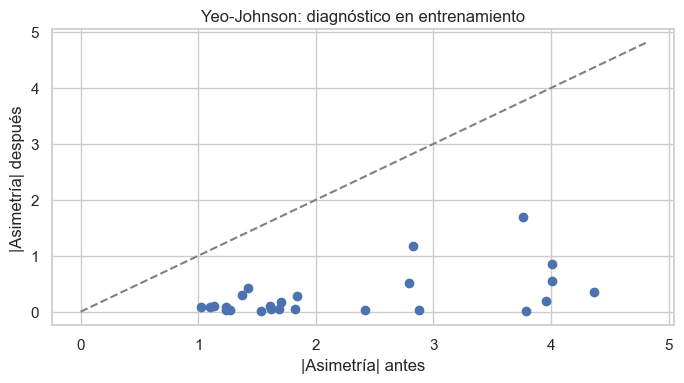

Variables numéricas escaladas: 89 | categóricas OHE: 6
Medias de numéricas (entrenamiento, max absoluto): 0.0


In [144]:
# Auditoría visual antes / después de las transformaciones
transform_report = pd.DataFrame(diagnostics,columns=['variable','skew_antes','skew_despues'])
if not transform_report.empty:
    transform_report['mejora_abs_asimetria']=transform_report.skew_antes.abs()-transform_report.skew_despues.abs()
    display(transform_report.sort_values('mejora_abs_asimetria',ascending=False).head(15))
    fig, ax=plt.subplots(figsize=(7,4))
    ax.scatter(transform_report.skew_antes.abs(),transform_report.skew_despues.abs())
    limit=max(1.,float(transform_report[['skew_antes','skew_despues']].abs().max().max())*1.1)
    ax.plot([0,limit],[0,limit],linestyle='--',color='gray')
    ax.set(xlabel='|Asimetría| antes',ylabel='|Asimetría| después',title='Yeo-Johnson: diagnóstico en entrenamiento')
    plt.tight_layout();plt.show()
else:
    print('No se aplicó Yeo-Johnson según los umbrales configurados.')
print('Variables numéricas escaladas:',len(num_cols),'| categóricas OHE:',Xtr_cat.shape[1])
print('Medias de numéricas (entrenamiento, max absoluto):',round(float(Xtr_num.mean().abs().max()),6))

### Análisis de resultados — Normalización y transformación

Se procesaron **89 características numéricas**, aplicando métodos de imputación, transformación y estandarización. De estas, 25 fueron transformadas mediante Yeo-Johnson para reducir su asimetría.

Los resultados muestran mejoras importantes en la distribución de algunas variables. Por ejemplo, la asimetría del plomo foliar de marzo disminuyó de 4.37 a 0.35, mientras que la del cobre foliar de marzo pasó de 3.79 a un valor cercano a cero.

Adicionalmente, se aplicó StandardScaler para estandarizar las variables y One-Hot Encoding para representar tratamiento y cultivar, obteniendo seis columnas categóricas.

Estas técnicas permiten preparar características con escalas comparables para los análisis posteriores. Los parámetros se calcularon con los datos de entrenamiento para evitar fuga de información.

# BLOQUE 3 · Selección y extracción 
## 3.1 Filtrado no supervisado

- **Varianza nula:** elimina columnas que no distinguen observaciones en entrenamiento.
- **Duplicados numéricos:** evita conservar dos columnas equivalentes.
- **Correlación Spearman** (|ρ| ≥ 0.95): reduce redundancia monotónica; el criterio es exploratorio y debe auditarse para no eliminar propiedades biológicas distintas solo por correlación.

Se preserva primero un **conjunto completo depurado**, que contiene los bloques del suelo, hoja nutricional y hoja RGB que sobrevivan a los filtros, junto a `Cultivar` y `Treatment`.

In [145]:
filter_log=[]
var=Xtr_num.var(ddof=0)
keep=[c for c in num_cols if var[c]>1e-12]
for c in num_cols:
    if c not in keep: filter_log.append({'variable':c,'motivo':'varianza nula'})
nondup=[]
for c in keep:
    copied=next((d for d in nondup if np.allclose(Xtr_num[c].to_numpy(),Xtr_num[d].to_numpy(),atol=1e-10,rtol=1e-10)),None)
    if copied: filter_log.append({'variable':c,'motivo':'duplicado de '+copied})
    else: nondup.append(c)
selected_corr=[]
for c in sorted(nondup,key=lambda s:(s.startswith('FE_'),s)):
    conflict=None
    for d in selected_corr:
        rho=spearmanr(Xtr_num[c],Xtr_num[d]).statistic
        if np.isfinite(rho) and abs(rho)>=0.95:
            conflict=(d,rho);break
    if conflict: filter_log.append({'variable':c,'motivo':f'Spearman {conflict[1]:.3f} con {conflict[0]}'})
    else: selected_corr.append(c)
assert selected_corr,'Ninguna variable sobrevivió al filtrado.'
Xtr_depurado=pd.concat([Xtr_num[selected_corr],Xtr_cat],axis=1)
Xte_depurado=pd.concat([Xte_num[selected_corr],Xte_cat],axis=1)
print('Iniciales:',len(num_cols),'| varianza:',len(keep),'| no duplicadas:',len(nondup),'| no redundantes:',len(selected_corr))
print('Matriz depurada + OHE:',Xtr_depurado.shape[1])

Iniciales: 89 | varianza: 89 | no duplicadas: 89 | no redundantes: 85
Matriz depurada + OHE: 91


## 3.2 Ranking F supervisado y selección científica por bloques

El ranking **F de regresión** evalúa la asociación individual con `yield_g/planta` (solo entrenamiento). Los p-valores son *exploratorios*, no pruebas inferenciales concluyentes del efecto de nutrientes. 

Se generan alternativas compactas de **12, 16 y 20** numéricas, con representación explícita de **suelo, nutrición foliar e indicadores RGB** siempre que haya candidatos suficientes. La asignación por bloque es una restricción científica exploratoria, no un resultado estadístico. Se conserva también el conjunto depurado completo.


In [146]:
def bloque(c):
    if c.startswith('soil_'):return 'Suelo'
    if c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_'):return 'RGB'
    if c.startswith('leaf_') or c.startswith('FE_delta_leaf_') or c.startswith('FE_ratio_'):return 'Nutrición'
    return 'Otro'
ytr=tr[TARGET].astype(float)
if len(selected_corr)>1 and ytr.nunique()>2:
    fs,pvs=f_regression(Xtr_num[selected_corr],ytr)
else:
    fs=np.full(len(selected_corr),np.nan);pvs=np.full(len(selected_corr),np.nan)
ranking=pd.DataFrame({'variable':selected_corr,'F':fs,'p_exploratorio':pvs})
ranking['F']=ranking.F.replace([np.inf,-np.inf],np.nan).fillna(-1)
ranking['bloque']=ranking.variable.map(bloque)
ranking=ranking.sort_values(['F','variable'],ascending=[False,True]).reset_index(drop=True)
# Límite por bloque es demostrativo y no una estimación de tamaño óptimo.
quotas={12:{'Suelo':4,'Nutrición':6,'RGB':2},16:{'Suelo':5,'Nutrición':8,'RGB':3},20:{'Suelo':6,'Nutrición':10,'RGB':4}}
def select_scientific(n):
    result=[]
    for b,lim in quotas[n].items():
        result.extend(ranking.loc[ranking.bloque.eq(b),'variable'].head(lim))
    # Repartir cupos no usados sin duplicados respetando el ranking.
    result=list(dict.fromkeys(result))
    result.extend([c for c in ranking.variable if c not in result][:max(0,n-len(result))])
    return result[:n]
sets={k:select_scientific(k) for k in quotas}
selection_summary=[]
for n,cols in sets.items():
    selected_blocks=pd.Series([bloque(c) for c in cols]).value_counts()
    selection_summary.append({'alternativa':f'Top {n}','numericas':len(cols),'Suelo':int(selected_blocks.get('Suelo',0)), 'Nutrición':int(selected_blocks.get('Nutrición',0)),'RGB':int(selected_blocks.get('RGB',0)),'con_OHE':len(cols)+Xtr_cat.shape[1]})
selection_report=pd.DataFrame(selection_summary)
display(selection_report)
display(ranking.head(25))
# Matriz compacta de referencia; NO significa que este n sea óptimo.
top=sets[12]
Xtr_selected=pd.concat([Xtr_num[top],Xtr_cat],axis=1)
Xte_selected=pd.concat([Xte_num[top],Xte_cat],axis=1)
filter_report=pd.DataFrame(filter_log,columns=['variable','motivo']).drop_duplicates()

,alternativa,numericas,Suelo,Nutrición,RGB,con_OHE
0,Top 12,12,4,6,2,18
1,Top 16,16,5,8,3,22
2,Top 20,20,6,10,4,26


,variable,F,p_exploratorio,bloque
0,leaf_nut_Mn_March,100.377795,1.166438e-09,Nutrición
1,leaf_nut_Ca_May,88.642750,3.573074e-09,Nutrición
2,FE_delta_leaf_nut_P,69.679461,2.893905e-08,Nutrición
3,leaf_nut_P_March,60.753819,9.068639e-08,Nutrición
4,leaf_nut_Mn_May,41.688377,1.700958e-06,Nutrición
5,leaf_rgb_GGA_March,40.833669,1.979799e-06,RGB
6,leaf_nut_Mg_March,37.530677,3.634133e-06,Nutrición
7,leaf_nut_Si_March,31.841118,1.128450e-05,Nutrición
8,FE_delta_leaf_nut_Co,30.352890,1.549366e-05,Nutrición
9,leaf_nut_S_March,27.881416,2.679746e-05,Nutrición


## 3.3 PCA: extracción de características

PCA trabaja con variables estandarizadas; aquí las categorías nominales se conservan fuera del PCA para mantener su significado.

**Umbral de referencia:** 85% de varianza acumulada. Se muestran cargas absolutas de PC1 y varianza por componente.



,componente,varianza_explicada,acumulada
0,PC1,0.258899,0.258899
1,PC2,0.094471,0.353370
2,PC3,0.086424,0.439795
3,PC4,0.069065,0.508860
4,PC5,0.063305,0.572164
5,PC6,0.061553,0.633718
6,PC7,0.055645,0.689363
7,PC8,0.042242,0.731604
8,PC9,0.037655,0.769259
9,PC10,0.032948,0.802208


,Carga PC1
leaf_nut_Mn_March,0.191032
leaf_nut_Ca_May,0.190320
leaf_nut_P_March,0.186759
leaf_nut_Mn_May,0.183912
FE_delta_leaf_nut_P,-0.181546
FE_delta_leaf_nut_Co,0.180494
leaf_nut_Mg_March,0.180206
FE_delta_leaf_nut_Fe,0.177612
leaf_rgb_GGA_March,0.176637
leaf_no3_mg NO3-/ 100 mg DW_March,-0.174731


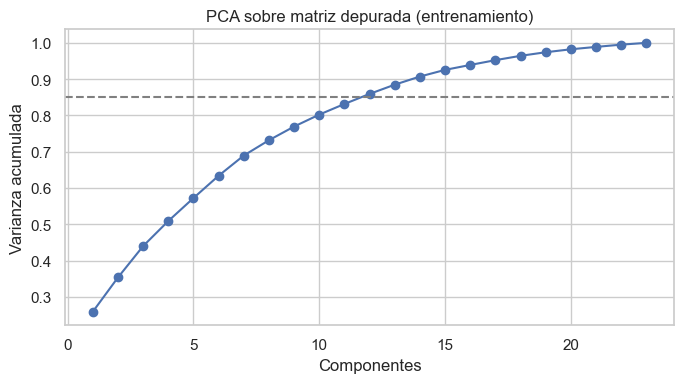

PCA: 12 componentes, varianza acumulada 85.93%


In [147]:
pca_base=selected_corr
max_comp=min(len(pca_base),len(Xtr_num)-1)
if max_comp>=2:
    pca_full=PCA(n_components=max_comp,random_state=54).fit(Xtr_num[pca_base])
    cum=np.cumsum(pca_full.explained_variance_ratio_)
    n_comp=min(max_comp,int(np.searchsorted(cum,0.85)+1))
    pca=PCA(n_components=n_comp,random_state=54)
    score_tr=pca.fit_transform(Xtr_num[pca_base]);score_te=pca.transform(Xte_num[pca_base])
    pca_cols=[f'PC{i+1}' for i in range(n_comp)]
    Xtr_pca=pd.concat([pd.DataFrame(score_tr,index=tr.index,columns=pca_cols),Xtr_cat],axis=1)
    Xte_pca=pd.concat([pd.DataFrame(score_te,index=te.index,columns=pca_cols),Xte_cat],axis=1)
    loading=pd.DataFrame(pca.components_.T,index=pca_base,columns=pca_cols)
    var_report=pd.DataFrame({'componente':pca_cols,'varianza_explicada':pca.explained_variance_ratio_, 'acumulada':np.cumsum(pca.explained_variance_ratio_)})
    display(var_report)
    display(loading['PC1'].loc[loading['PC1'].abs().sort_values(ascending=False).index].head(12).rename('Carga PC1').to_frame())
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(range(1,len(cum)+1),cum,marker='o');ax.axhline(0.85,linestyle='--',color='gray')
    ax.set(xlabel='Componentes',ylabel='Varianza acumulada',title='PCA sobre matriz depurada (entrenamiento)')
    plt.tight_layout();fig.savefig(FIG/'pca_varianza_fe.png',dpi=140);plt.show()
    print(f'PCA: {n_comp} componentes, varianza acumulada {100*var_report.acumulada.iloc[-1]:.2f}%')
else:
    pca=None;n_comp=0; loading=pd.DataFrame();var_report=pd.DataFrame()
    Xtr_pca=Xtr_depurado.copy();Xte_pca=Xte_depurado.copy()
    print('No existen suficientes dimensiones para PCA.')

### Análisis de resultados — Selección y extracción de características

Se aplicaron filtros de varianza, duplicación y correlación de Spearman sobre 89 características numéricas. No se eliminaron variables por varianza nula ni por duplicación exacta; sin embargo, se descartaron **cuatro variables por correlación elevada**, conservando 85 características numéricas depuradas.

Posteriormente, se generaron tres alternativas de selección supervisada: Top 12, Top 16 y Top 20, manteniendo representación de las propiedades del suelo, la nutrición foliar y los indicadores RGB de las hojas.

También se aplicó PCA, logrando representar las 85 características numéricas mediante **12 componentes principales que explican el 85.93% de la varianza**.

Estos resultados demuestran que es posible reducir la dimensionalidad de los datos conservando una proporción importante de su variabilidad. No obstante, la selección definitiva deberá evaluarse durante el modelado, ya que una menor cantidad de variables no garantiza un mejor rendimiento predictivo.

## 4. Exportación, trazabilidad y controles

Se exportan *por separado* los conjuntos completos depurados, alternativas Top 12/16/20 y PCA, cada uno con train/test.



In [148]:
def write_matrix(x,meta,name):
    frame=pd.concat([meta[ID+[TARGET]].reset_index(drop=True),x.reset_index(drop=True)],axis=1)
    frame.to_csv(OUT/name,index=False)
    return frame
write_matrix(Xtr_depurado,tr,'train_depurado.csv')
write_matrix(Xte_depurado,te,'test_depurado.csv')
for n,cols in sets.items():
    write_matrix(pd.concat([Xtr_num[cols],Xtr_cat],axis=1),tr,f'train_top_{n}.csv')
    write_matrix(pd.concat([Xte_num[cols],Xte_cat],axis=1),te,f'test_top_{n}.csv')
write_matrix(Xtr_pca,tr,'train_pca.csv')
write_matrix(Xte_pca,te,'test_pca.csv')
filter_report.to_csv(OUT/'variables_descartadas.csv',index=False)
ranking.to_csv(OUT/'ranking_f_rendimiento.csv',index=False)
selection_report.to_csv(OUT/'comparacion_subconjuntos.csv',index=False)
pd.DataFrame([{'variable':k,'justificacion':v} for k,v in derived.items()]).to_csv(OUT/'diccionario_derivadas.csv',index=False)
transform_report.to_csv(OUT/'auditoria_transformaciones.csv',index=False)
if not var_report.empty:var_report.to_csv(OUT/'pca_varianza.csv',index=False)
if not loading.empty:loading.to_csv(OUT/'pca_cargas.csv',index_label='variable')
assert set(tr.parcela_provisional).isdisjoint(set(te.parcela_provisional))
assert Xtr_depurado.columns.equals(Xte_depurado.columns)
assert Xtr_depurado.notna().all().all() and Xte_depurado.notna().all().all()
print('Archivos exportados a',OUT)

Archivos exportados a C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\feature_engineering


# Conclusiones de Preparación de datos — CRISP-ML(Q)

### Conclusiones generales de Feature Engineering

La fase de Ingeniería de Características permitió transformar los datos originales del estudio de fresas Donna y Dream en conjuntos de variables preparados para las siguientes etapas de aprendizaje automático.

Se construyeron **25 características derivadas**, se procesaron 89 variables numéricas mediante técnicas de imputación, transformación y estandarización, y se codificaron las variables categóricas de tratamiento y cultivar.

Posteriormente, se aplicaron técnicas de selección y extracción que permitieron conservar 85 características numéricas depuradas, generar alternativas de selección por bloques científicos y obtener 12 componentes principales que explican el 85.93% de la varianza.

Estas decisiones se alinean con los objetivos del estudio, al conservar información sobre las propiedades del suelo, la nutrición foliar y los indicadores RGB, potencialmente relacionados con la producción y calidad de las fresas.


In [149]:
resumen=pd.DataFrame([
 {'indicador':'Filas analíticas','resultado':len(ana)},
 {'indicador':'Grupos provisionales','resultado':ana.parcela_provisional.nunique()},
 {'indicador':'Características derivadas','resultado':len(derived)},
 {'indicador':'Yeo-Johnson aplicadas','resultado':len(transformers)},
 {'indicador':'Numéricas candidatas','resultado':len(num_cols)},
 {'indicador':'Numéricas depuradas','resultado':len(selected_corr)},
 {'indicador':'Codificadas OHE','resultado':Xtr_cat.shape[1]},
 {'indicador':'PCA componentes','resultado':n_comp},
 {'indicador':'PCA varianza acumulada (%)','resultado':round(100*float(var_report.acumulada.iloc[-1]),2) if not var_report.empty else np.nan},
 {'indicador':'Train/Test','resultado':f'{len(tr)}/{len(te)}'}
])
display(resumen)
resumen.to_csv(OUT/'resumen_preparacion_crisp_ml.csv',index=False)

,indicador,resultado
0,Filas analíticas,32
1,Grupos provisionales,16
2,Características derivadas,25
3,Yeo-Johnson aplicadas,25
4,Numéricas candidatas,89
5,Numéricas depuradas,85
6,Codificadas OHE,6
7,PCA componentes,12
8,PCA varianza acumulada (%),85.93
9,Train/Test,24/8
